# Monthly Price Forecasting — Internship Project

## 1. Project Overview

### Business Objective
The objective of this project is to analyze historical monthly price data
and forecast the average monthly price for the next 12 months.

### Project Workflow
1. Data understanding and validation
2. Data cleaning and preprocessing
3. Exploratory Data Analysis (EDA)
4. Time-series analysis
5. Forecasting model development
6. Model evaluation and comparison
7. Future price forecasting
8. Business recommendations
9. Production deployment architecture
10. Model monitoring

### Dataset
- File: price_data.csv
- Date column: date
- Target variable: avg_monthly_price

In [1]:
# 1. IMPORTNG REQUIRED LIBRARIES
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

# Visualization configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully!")
print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

Libraries imported successfully!
Python Version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Pandas Version: 3.1.0
NumPy Version: 2.5.4


In [11]:
# 2. LOAD THE DATASET
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "price_data.csv"

print("Project Root:", PROJECT_ROOT)
print("Dataset Path:", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}"
    )

Project Root: d:\BECAME_DEVELOPER\PriceForecastingW2A
Dataset Path: d:\BECAME_DEVELOPER\PriceForecastingW2A\data\raw\price_data.csv


In [12]:
df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)


Dataset loaded successfully!
Dataset Shape: (249, 2)


In [4]:
# Dataset Understanding
print("FIRST 10 RECORDS")
display(df.head(10))

print("\nLAST 10 RECORDS")
display(df.tail(10))

FIRST 10 RECORDS


,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876
5,2005-06-01,5058
6,2005-07-01,4919
7,2005-08-01,5149
8,2005-09-01,4899
9,2005-10-01,4562



LAST 10 RECORDS


,date,avg_monthly_price
239,2024-12-01,12250
240,2025-01-01,11313
241,2025-02-01,11313
242,2025-03-01,14188
243,2025-04-01,14263
244,2025-05-01,14263
245,2025-06-01,14263
246,2025-07-01,16000
247,2025-08-01,15025
248,2025-09-01,15750


In [5]:
print("\nCOLUMN NAMES")
print(df.columns.tolist())


COLUMN NAMES
['date', 'avg_monthly_price']


In [6]:
print("\nDATA TYPES")
print(df.dtypes)


DATA TYPES
date                   str
avg_monthly_price    int64
dtype: object


In [8]:
print("\nDATASET INFORMATION")
df.info()


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   date               249 non-null    str  
 1   avg_monthly_price  249 non-null    int64
dtypes: int64(1), str(1)
memory usage: 4.0 KB


In [9]:
display(df.describe(include="all"))

,date,avg_monthly_price
count,249,249.000000
unique,249,NaN
top,2005-01-01,NaN
freq,1,NaN
mean,NaN,7918.891566
std,NaN,2804.992684
min,NaN,3500.000000
25%,NaN,6123.000000
50%,NaN,7250.000000
75%,NaN,9783.000000


#### Data Cleaning and sort

- Time-series models require dates in a proper datetime format.

In [14]:
# convert date
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values("date").reset_index(drop=True)

print("Date conversion completed.")
print(df.dtypes)

Date conversion completed.
date                 datetime64[us]
avg_monthly_price             int64
dtype: object


In [15]:
print("Missing values:")
display(df.isnull().sum())

Missing values:


date                 0
avg_monthly_price    0
dtype: int64

In [16]:

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["date"].duplicated().sum())


Duplicate rows: 0
Duplicate dates: 0


In [17]:
print("\nInvalid dates:", df["date"].isna().sum())
print("Invalid prices:", df["avg_monthly_price"].isna().sum())


Invalid dates: 0
Invalid prices: 0


In [18]:
print("Zero or negative prices:",
      (df["avg_monthly_price"] <= 0).sum())

Zero or negative prices: 0


In [19]:
print("\nDate range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())


Date range:
Start: 2005-01-01 00:00:00
End: 2025-09-01 00:00:00


In [20]:
print("\nPrice range:")
print("Minimum:", df["avg_monthly_price"].min())
print("Maximum:", df["avg_monthly_price"].max())


Price range:
Minimum: 3500
Maximum: 16163


In [21]:
expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="MS"
)

actual_dates = pd.DatetimeIndex(df["date"])

missing_months = expected_dates.difference(actual_dates)

print("Expected monthly records:", len(expected_dates))
print("Actual monthly records:", len(actual_dates))
print("Missing months:", len(missing_months))

if len(missing_months) > 0:
    print(missing_months)
else:
    print("All months are present.")

Expected monthly records: 249
Actual monthly records: 249
Missing months: 0
All months are present.


- Above the data shows as contain 1st of every month from 2005 to 2025.
- (20 yrs * 12) + 9 = 249
- Missing months can affect forecasting accuracy and seasonal analysis.

## Exploratory Data Analysis

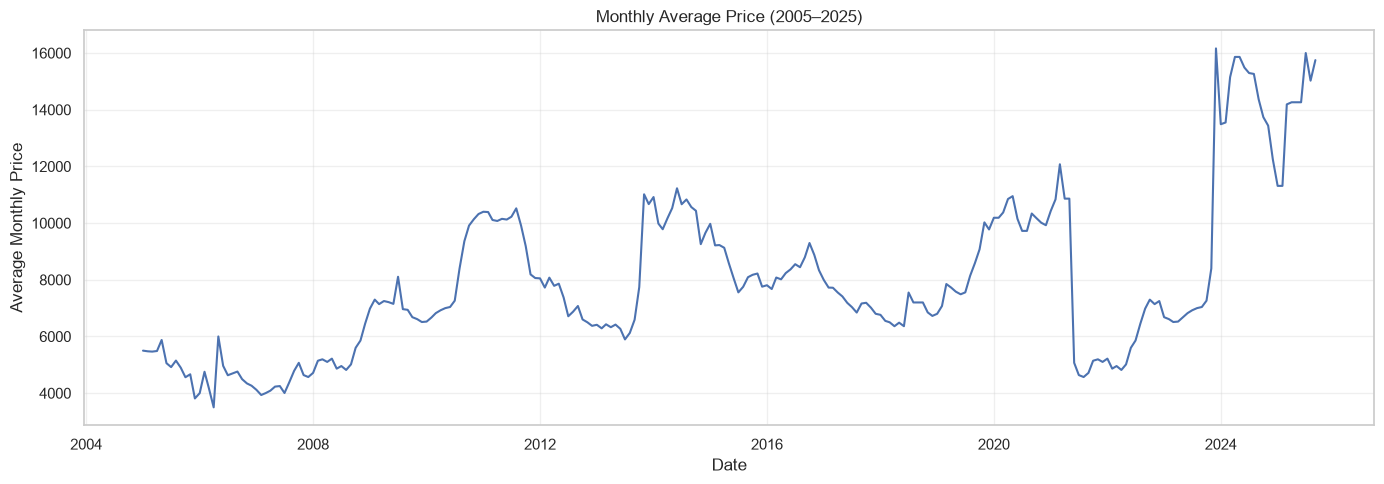

In [22]:
plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["avg_monthly_price"], linewidth=1.5)

plt.title("Monthly Average Price (2005–2025)")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

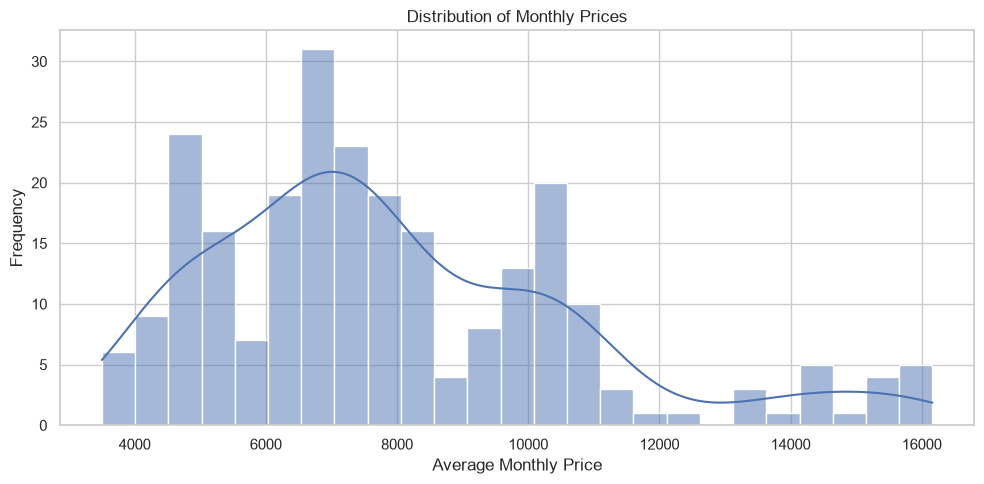

In [23]:
# checking price dist
plt.figure(figsize=(10, 5))

sns.histplot(df["avg_monthly_price"], bins=25, kde=True)

plt.title("Distribution of Monthly Prices")
plt.xlabel("Average Monthly Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
# calculate yearly average
df["year"] = df["date"].dt.year

yearly_avg = df.groupby("year")["avg_monthly_price"].mean()

display(yearly_avg.round(2).to_frame("Average Price"))

,Average Price
year,
2005,5072.50
2006,4548.75
2007,4339.92
2008,5244.50
2009,7070.67
2010,8031.25
2011,9778.83
2012,7251.00
2013,7181.92


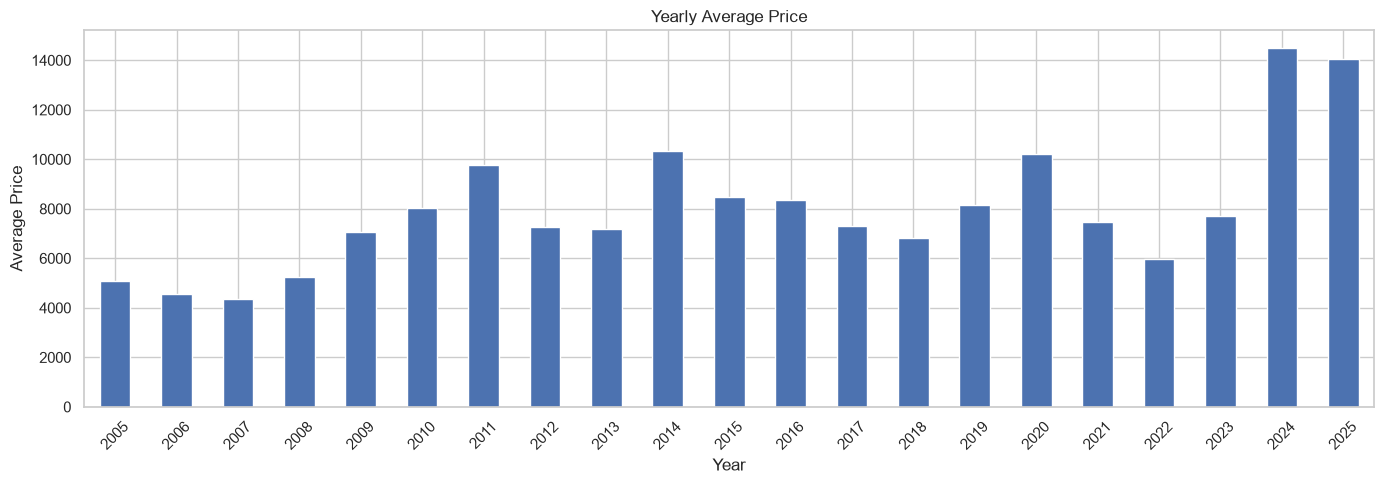

In [25]:
plt.figure(figsize=(14, 5))

yearly_avg.plot(kind="bar")

plt.title("Yearly Average Price")
plt.xlabel("Year")
plt.ylabel("Average Price")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
# calculate monthly pct change
df["monthly_change"] = df["avg_monthly_price"].pct_change() * 100

display(
    df[["date", "avg_monthly_price", "monthly_change"]].tail(15)
)

,date,avg_monthly_price,monthly_change
234,2024-07-01,15294,-1.252583
235,2024-08-01,15263,-0.202694
236,2024-09-01,14363,-5.896613
237,2024-10-01,13738,-4.351459
238,2024-11-01,13438,-2.183724
239,2024-12-01,12250,-8.840601
240,2025-01-01,11313,-7.648980
241,2025-02-01,11313,0.000000
242,2025-03-01,14188,25.413241
243,2025-04-01,14263,0.528616


- Don't remove any outliers yet.


### EDA Observations:
- Prices generally increased between 2005 and 2025, but there are periods of decline.
- noticeable changes around 2011, 2014, 2021 and 2024.
- The histogram is right-skewed, with a smaller number of observations at higher price levels.
- March 2025 recorded a 25.41% increase, while July 2025 recorded a 12.18% increase.
- 2025 contains only January–September data, so its yearly average is not directly comparable with complete years.
- Further analysis is required.

## Outlier and anomaly analysis


In [28]:
change_stats = df["monthly_change"].dropna()

median_change = change_stats.median()
mad = (change_stats - median_change).abs().median()

if mad > 0:
    df["modified_z_score"] = (
        0.6745 * (df["monthly_change"] - median_change) / mad
    )
else:
    df["modified_z_score"] = np.nan

df["anomaly_flag"] = df["modified_z_score"].abs() > 3.5

print("Median monthly change:", round(median_change, 2))
print("MAD:", round(mad, 2))
print("Potential anomalies:", df["anomaly_flag"].sum())

display(
    df.loc[
        df["anomaly_flag"],
        ["date", "avg_monthly_price", "monthly_change", "modified_z_score"]
    ]
)

Median monthly change: 0.0
MAD: 2.9
Potential anomalies: 14


,date,avg_monthly_price,monthly_change,modified_z_score
11,2005-12-01,3813,-18.263666,-4.252146
13,2006-02-01,4755,18.875000,4.394477
15,2006-04-01,3500,-16.187739,-3.768829
16,2006-05-01,6000,71.428571,16.629998
17,2006-06-01,4964,-17.266667,-4.020025
67,2010-08-01,8400,15.670614,3.648432
105,2013-10-01,7744,17.511381,4.076999
106,2013-11-01,11016,42.252066,9.837125
162,2018-07-01,7550,18.673373,4.347534
197,2021-06-01,5070,-53.327810,-12.415779


- Modified Z-score uses the median and median absolute deviation, making it less sensitive to extreme changes than a standard Z-score
- some large movements are followed by movements in the opposite direction. This may indicate temporary price shocks

In [29]:
largest_changes = df.loc[
    df["monthly_change"].abs().nlargest(10).index,
    ["date", "avg_monthly_price", "monthly_change"]
].sort_values("monthly_change", key=abs, ascending=False)

display(largest_changes)

,date,avg_monthly_price,monthly_change
227,2023-12-01,16163,92.416667
16,2006-05-01,6000,71.428571
197,2021-06-01,5070,-53.327810
106,2013-11-01,11016,42.252066
242,2025-03-01,14188,25.413241
13,2006-02-01,4755,18.875000
162,2018-07-01,7550,18.673373
11,2005-12-01,3813,-18.263666
105,2013-10-01,7744,17.511381
17,2006-06-01,4964,-17.266667


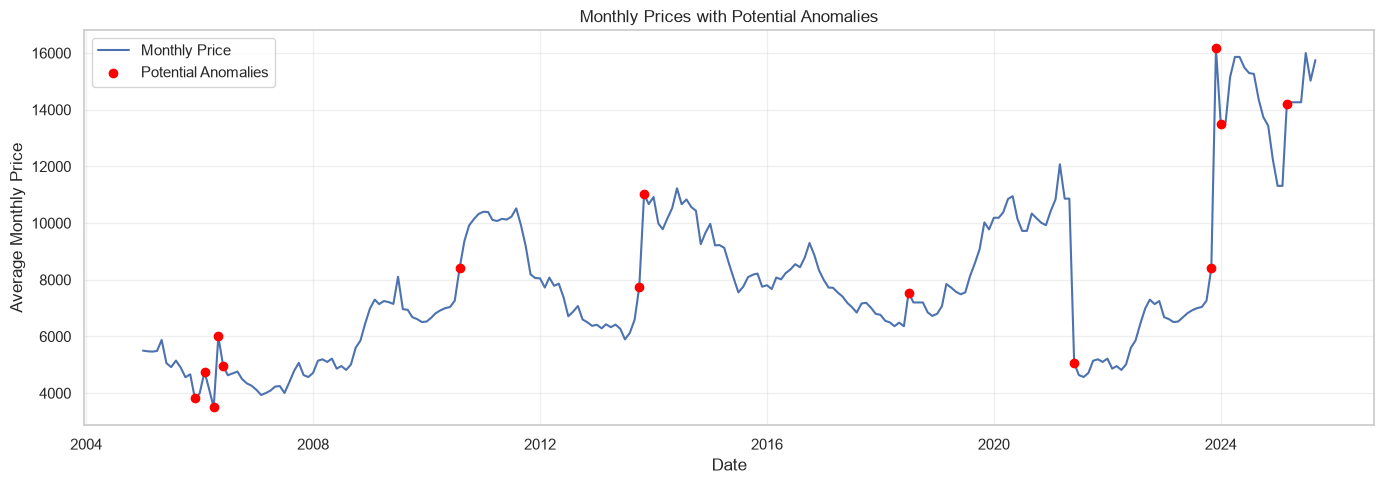

In [30]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["avg_monthly_price"],
    label="Monthly Price"
)

anomalies = df[df["anomaly_flag"]]

plt.scatter(
    anomalies["date"],
    anomalies["avg_monthly_price"],
    color="red",
    label="Potential Anomalies",
    zorder=3
)

plt.title("Monthly Prices with Potential Anomalies")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Anomaly Analysis

- 14 potential anomalies were identified using the Modified Z-score method.
- Major price movements occurred in 2006, 2013, 2021, 2023 and 2025.
- Some sharp movements were followed by reversals.
- All original observations are retained for forecasting.

## Time-series preparation

In [31]:
# creating time series
ts = df.set_index("date")["avg_monthly_price"].asfreq("MS")

print("Time series created.")
print("Frequency:", ts.index.freq)
print("Observations:", len(ts))
print("Missing values:", ts.isna().sum())

display(ts.head())
display(ts.tail())

Time series created.
Frequency: <MonthBegin>
Observations: 249
Missing values: 0


date
2005-01-01    5500
2005-02-01    5476
2005-03-01    5466
2005-04-01    5487
2005-05-01    5876
Freq: MS, Name: avg_monthly_price, dtype: int64

date
2025-05-01    14263
2025-06-01    14263
2025-07-01    16000
2025-08-01    15025
2025-09-01    15750
Freq: MS, Name: avg_monthly_price, dtype: int64

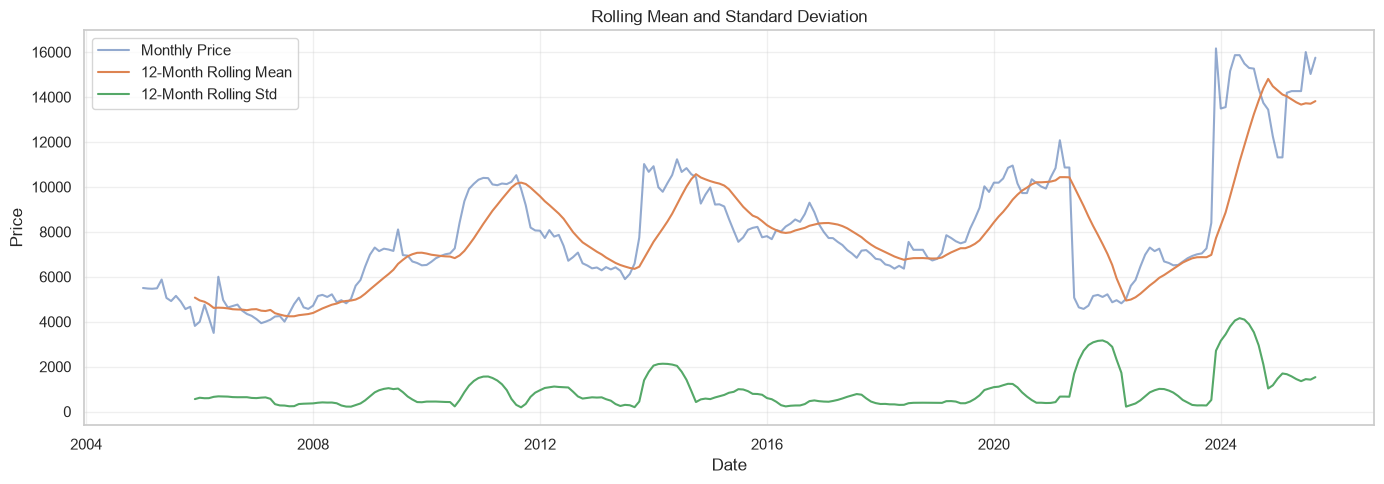

In [ ]:
# rolling mean and standard deviation
rolling_mean = ts.rolling(window=12).mean()
rolling_std = ts.rolling(window=12).std()

plt.figure(figsize=(14, 5))

plt.plot(ts, label="Monthly Price", alpha=0.6)
plt.plot(rolling_mean, label="12-Month Rolling Mean")
plt.plot(rolling_std, label="12-Month Rolling Std")

plt.title("Rolling Mean and Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# monthly seasonality
monthly_avg = df.groupby(
    df["date"].dt.month
)["avg_monthly_price"].mean()

display(monthly_avg.round(2).to_frame("Average Price"))

,Average Price
date,
1,7822.48
2,7774.67
3,8086.86
4,8032.43
5,8210.24
6,7770.19
7,7812.67
8,7865.52
9,8044.38


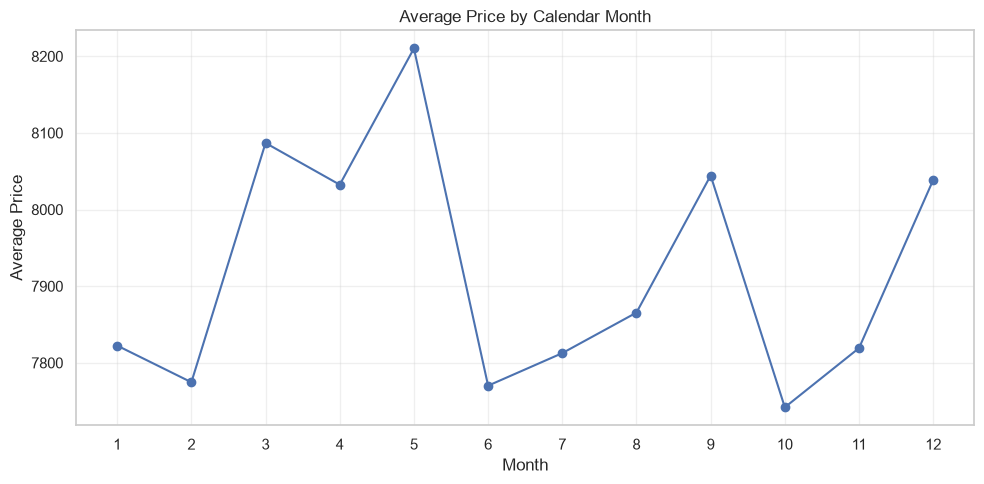

In [34]:
plt.figure(figsize=(10, 5))

monthly_avg.plot(marker="o")

plt.title("Average Price by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Price")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
train = ts.iloc[:-12]
test = ts.iloc[-12:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Training records:", len(train))

print("\nTesting period:", test.index.min(), "to", test.index.max())
print("Testing records:", len(test))

Training period: 2005-01-01 00:00:00 to 2024-09-01 00:00:00
Training records: 237

Testing period: 2024-10-01 00:00:00 to 2025-09-01 00:00:00
Testing records: 12


### Time Series Observations

- The series shows an overall upward trend.
- Price variability changes over time.
- Monthly averages show some seasonal differences.
- Training data contains 237 observations.
- Testing data contains the final 12 observations.

## Time-series decomposition and stationarity

In [36]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

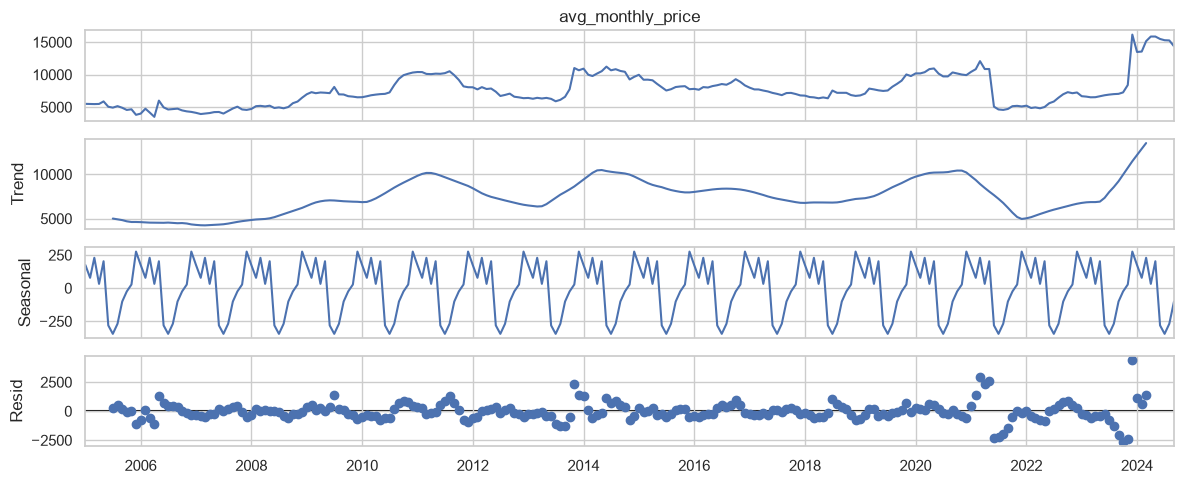

In [37]:
decomposition = seasonal_decompose(
    train,
    model="additive",
    period=12
)

decomposition.plot()
plt.tight_layout()
plt.show()

- Trend: long-term price movement.
- Seasonal: repeating annual pattern.
- Residual: remaining unexplained variation

In [38]:
adf_result = adfuller(train)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

if adf_result[1] <= 0.05:
    print("The series is stationary.")
else:
    print("The series is non-stationary.")

ADF Statistic: -1.898
p-value: 0.333
The series is non-stationary.


In [39]:
train_diff = train.diff().dropna()

adf_diff = adfuller(train_diff)

print("ADF Statistic:", round(adf_diff[0], 4))
print("p-value:", round(adf_diff[1], 4))

if adf_diff[1] <= 0.05:
    print("Differenced series is stationary.")
else:
    print("Differenced series is non-stationary.")

ADF Statistic: -15.7668
p-value: 0.0
Differenced series is stationary.


|Test|Result|Interpretation|
|---|---|---|
|Original ADF p-value|0.333|Non-stationary|
|First-differenced ADF p-value|0.000|Stationary|